# Insights into Student Performance and Contributing Factors

**Dataset Download Link:** https://www.kaggle.com/datasets/lainguyn123/student-performance-factors/data

The source of this dataset by lainguyn123 was created to simulate real-life scenarios of student performance but does not come from actual schools. It contains data about 6,607 students and 20 features such as study habits, attendance, parental involvement, and access to resources. This assessment aims to predict whether a student will pass or fail based on different factors that affect their academic performance. (It provides an overview of various aspects that influence a student's exam scores)

The dataset used in this analysis contained 6,607 entries and 20 columns, incorporating a mix of numerical and categorical variables. Key features included academic factors like Hours_Studied, Attendance, and Previous_Scores, along with personal characteristics such as Motivation_Level, Gender, and Parental_Education_Level, and socioeconomic influences like Family_Income and Access_to_Resources. While the dataset was largely complete, a few columns such as Teacher_Quality (78 missing entries), Parental_Education_Level (90 missing entries), and Distance_from_Home (67 missing entries) had missing values, which were appropriately handled during preprocessing. The dataset provided a solid foundation for evaluating the predictive performance of machine learning models in forecasting student exam scores.

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, roc_auc_score
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sn

# Load the dataset from the specified location
data = pd.read_csv('/kaggle/input/datasets/jamessalcedo/student-factors/StudentPerformanceFactors.csv')

# Check for missing values in the dataset
print(data.isnull().sum())

# Handling missing values for numeric columns
# Filling missing values in numeric columns with the mean of each column
numeric_cols = data.select_dtypes(include=['float64', 'int64']).columns
data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].mean())

# Handling missing values for categorical columns
# Filling missing values in categorical columns with the most common value (mode)
categorical_cols = data.select_dtypes(include=['object']).columns
for col in categorical_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

# Encoding categorical variables
# Converts categorical data into dummy/indicator variables (1/0)
# drop_first=True drops the first category to avoid multicollinearity issues
data_encoded = pd.get_dummies(data, drop_first=True)

# Creating a new column 'Pass_Fail' based on the 'Exam_Score' column
# If a student scored above 60, they are labeled as Pass (1); otherwise, Fail (0)
data_encoded['Pass_Fail'] = data_encoded['Exam_Score'].apply(lambda x: 1 if x > 60 else 0)

# Dropping the original 'Exam_Score' column as it's no longer needed
data_encoded.drop(columns=['Exam_Score'], inplace=True)

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64


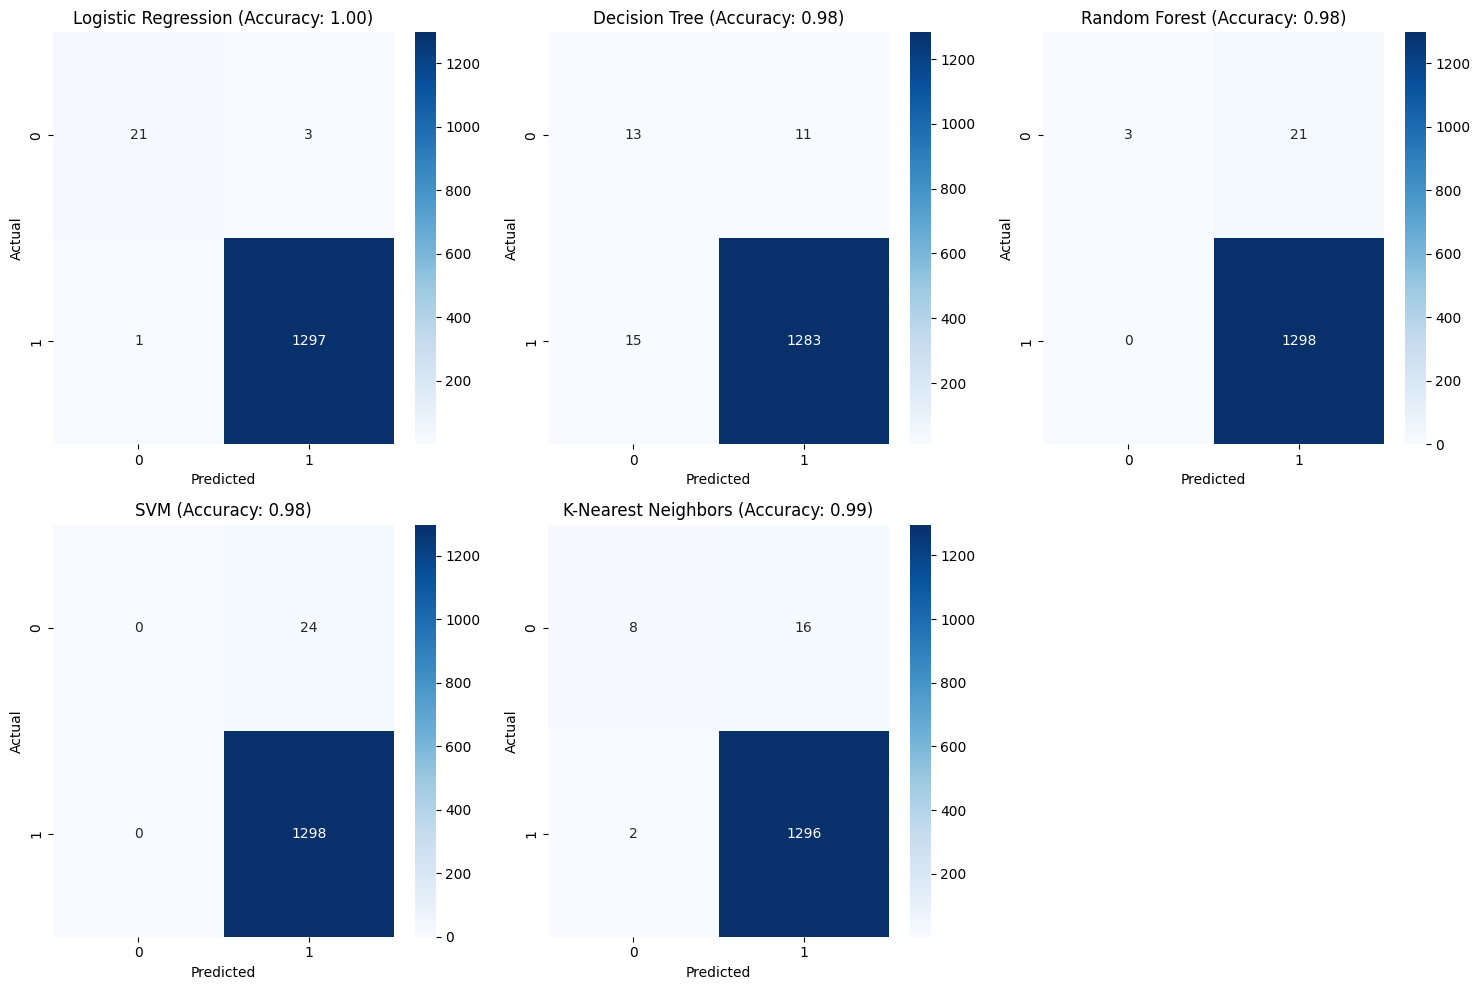

In [13]:
# Defining the feature set (X) and the target variable (y)
X = data_encoded.drop(columns=['Pass_Fail'])
y = data_encoded['Pass_Fail']

# Splitting the dataset into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Classifiers to be used
classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'SVM': SVC(),
    'K-Nearest Neighbors': KNeighborsClassifier()
}

# Dictionary to store results (accuracy and confusion matrix) for each model
results = {}

# Training and evaluating each classifier
for name, clf in classifiers.items():
    clf.fit(X_train, y_train) # Train the classifier on the training data
    y_pred = clf.predict(X_test) # Make predictions on the testing data
    accuracy = accuracy_score(y_test, y_pred) # Calculate the accuracy of the model
    cm = confusion_matrix(y_test, y_pred) # Generate the confusion matrix for the model
    results[name] = {'accuracy': accuracy, 'confusion_matrix': cm} # Store the results (accuracy and confusion matrix)

# Plotting the confusion matrices for each classifier
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()  # Flatten the axes array for easy indexing

# Loop through the results and plot each confusion matrix
for i, (name, result) in enumerate(results.items()):
    sns.heatmap(result['confusion_matrix'], annot=True, fmt="d", cmap='Blues', ax=axes[i])
    axes[i].set_title(f'{name} (Accuracy: {result["accuracy"]:.2f})')  # Title with accuracy
    axes[i].set_xlabel('Predicted')  # X-axis label
    axes[i].set_ylabel('Actual')  # Y-axis label

# Turn off the last axis if it's unused
axes[-1].axis('off')

# Adjust the layout of the plots for better visualization
plt.tight_layout()

# Show the plot
plt.show()

# Conclusion #1

In this assessment, different classification techniques are used to predict whether students would pass or fail based on factors like their study habits, attendance, and family background. All the models performed well, with Logistic Regression achieving the highest accuracy. The dataset and models helped us understand what influences a student's chances of success in exams. It’s clear that factors like study time and parental involvement can really make a difference. Overall, this classified dataset by lainguyn123 provided us with valuable insights into how we can better support our fellow students in achieving their academic goals.

In [11]:
data = pd.read_csv('/kaggle/input/datasets/jamessalcedo/student-factors/StudentPerformanceFactors.csv')

# Show dataset overview
print("Dataset Overview:")
print(data.info())  # Check for missing values and data types
print("\nFirst few rows of the dataset:")
print(data.head())  # Check the first few rows

Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              66

In [14]:
# Preprocessing
# Encode categorical variables (converts categorical columns to numeric form)
categorical_columns = [
    'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities',
    'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality',
    'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level',
    'Distance_from_Home', 'Gender'
]

In [16]:
label_encoders = {}  # To store label encoders for later inverse transformations
for col in categorical_columns:
    le = LabelEncoder()
    data[col] = le.fit_transform(data[col])  # Encode labels to numeric
    label_encoders[col] = le  # Store the label encoder for each column

# Features and Target variables
X = data.drop(columns=['Exam_Score'])  # Features are all columns except the target
y = data['Exam_Score']  # Target variable is 'Exam_Score'

# Normalize numeric features (scaling numerical columns to standardize their values)
scaler = StandardScaler()
numeric_columns = ['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']
X[numeric_columns] = scaler.fit_transform(X[numeric_columns])  # Standardize the selected numeric columns

# Convert target to binary classification (High Score vs Low Score)
median_score = y.median()  # Determine the median of exam scores to create a binary target
y = (y >= median_score).astype(int)  # 1 for High Score (above median), 0 for Low Score (below median)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # 80% for training, 20% for testing

# SMOTE - Balancing the dataset (to deal with imbalanced classes in target variable)
smote = SMOTE(random_state=42)  # SMOTE stands for Synthetic Minority Over-sampling Technique
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)  # Generate synthetic samples for the minority class

# Experiment 1

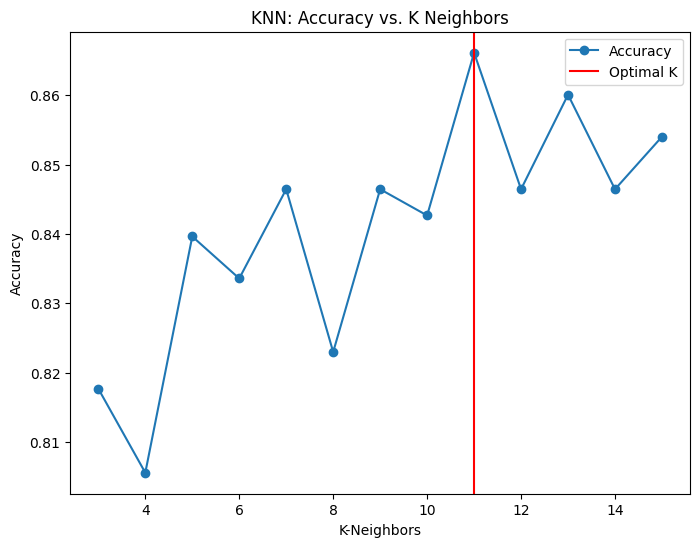

Best K: 11, Accuracy: 0.87

Confusion Matrix (KNN):
[[509  58]
 [119 636]]


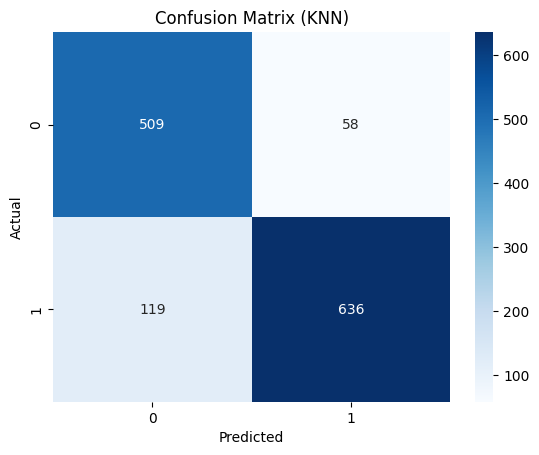

In [17]:
# --- Experiment 1: K-Nearest Neighbors (KNN) ---
# Varying values of K to find the optimal number of neighbors for KNN
k_values = range(3, 16)
knn_accuracies = []  # To store accuracy for each value of K

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_res, y_train_res)  # Train KNN with balanced training set
    y_pred = knn.predict(X_test)  # Make predictions on the test set
    knn_accuracies.append(accuracy_score(y_test, y_pred))  # Record accuracy for this value of K

# Plot accuracy vs. K
plt.figure(figsize=(8, 6))
plt.plot(k_values, knn_accuracies, marker='o', label="Accuracy")
plt.axvline(x=k_values[np.argmax(knn_accuracies)], color='red', linestyle='-', label="Optimal K")
plt.xlabel('K-Neighbors')
plt.ylabel('Accuracy')
plt.title('KNN: Accuracy vs. K Neighbors')
plt.legend()
plt.show()

# Best K and its accuracy
best_k = k_values[np.argmax(knn_accuracies)]
print(f"Best K: {best_k}, Accuracy: {max(knn_accuracies):.2f}")

# Confusion Matrix for Best K
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_res, y_train_res)
y_pred_knn = knn_best.predict(X_test)
conf_matrix_knn = confusion_matrix(y_test, y_pred_knn)
print("\nConfusion Matrix (KNN):")
print(conf_matrix_knn)
sns.heatmap(conf_matrix_knn, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (KNN)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Experiment 2


Classification Report (Logistic Regression):
              precision    recall  f1-score   support

           0       0.86      0.89      0.87       567
           1       0.92      0.89      0.90       755

    accuracy                           0.89      1322
   macro avg       0.89      0.89      0.89      1322
weighted avg       0.89      0.89      0.89      1322

Logistic Regression AUC Score: 0.966


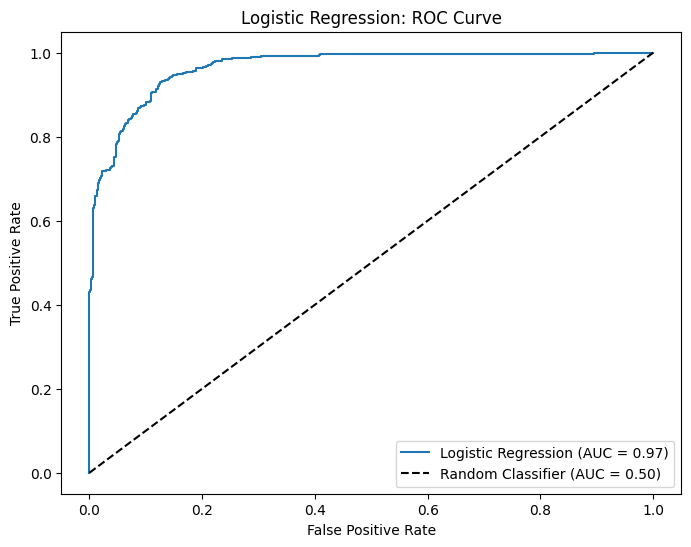


Confusion Matrix (Logistic Regression):
[[505  62]
 [ 85 670]]


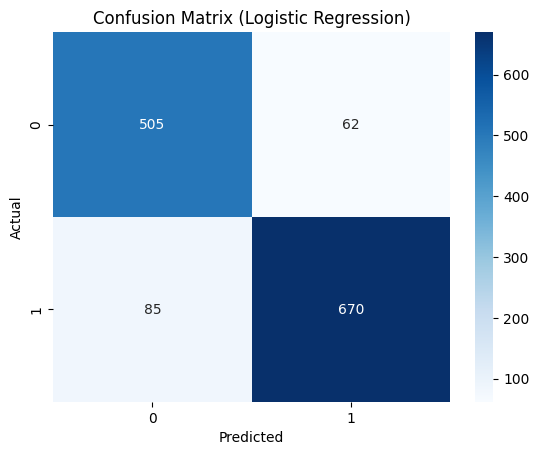

In [18]:
# --- Experiment 2: Logistic Regression ---
# Logistic Regression with class weights to handle class imbalance
lr = LogisticRegression(class_weight='balanced')
lr.fit(X_train_res, y_train_res)
y_pred_lr = lr.predict(X_test)

# Classification report
print("\nClassification Report (Logistic Regression):")
print(classification_report(y_test, y_pred_lr))

# ROC Curve and AUC for Logistic Regression
y_prob_lr = lr.predict_proba(X_test)[:, 1]  # Get probabilities for the positive class
fpr, tpr, _ = roc_curve(y_test, y_prob_lr)  # Compute False Positive Rate and True Positive Rate
auc_score = roc_auc_score(y_test, y_prob_lr)  # Compute AUC (Area Under Curve)
print(f"Logistic Regression AUC Score: {auc_score:.3f}")

# Plot ROC Curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Logistic Regression (AUC = {:.2f})".format(auc_score))
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier (AUC = 0.50)")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression: ROC Curve')
plt.legend()
plt.show()

# Confusion Matrix for Logistic Regression
conf_matrix_lr = confusion_matrix(y_test, y_pred_lr)
print("\nConfusion Matrix (Logistic Regression):")
print(conf_matrix_lr)

# Plot Confusion Matrix for Logistic Regression
sns.heatmap(conf_matrix_lr, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (Logistic Regression)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Experiment 3

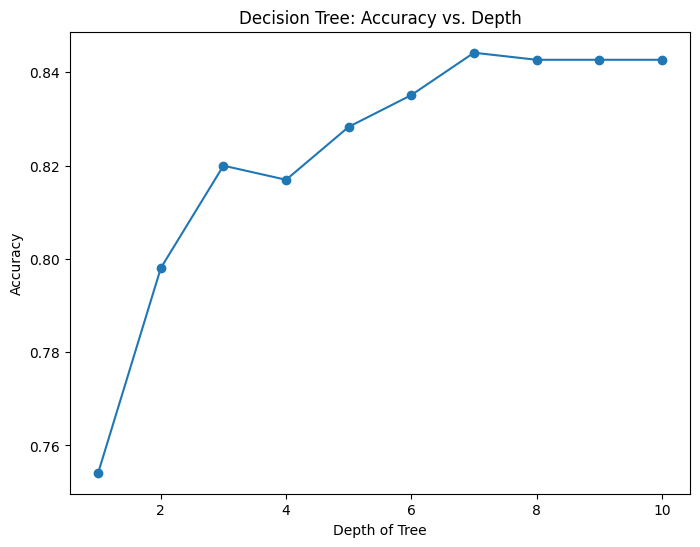

Best Depth: 7, Accuracy: 0.84

Confusion Matrix (Decision Tree):
[[482  85]
 [121 634]]


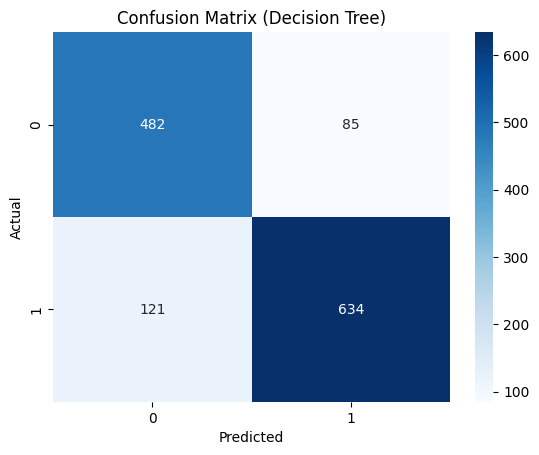

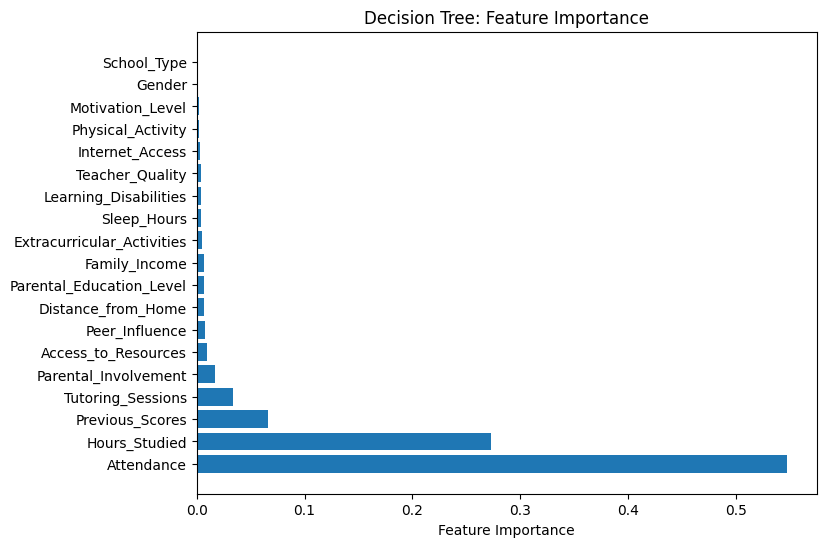

In [19]:
# --- Experiment 3: Decision Tree ---
# Varying tree depth to find the optimal depth for Decision Tree
depths = range(1, 11)
dt_accuracies = []  # To store accuracy for each tree depth

for depth in depths:
    dt = DecisionTreeClassifier(max_depth=depth, random_state=42, class_weight='balanced')
    dt.fit(X_train_res, y_train_res)
    y_pred = dt.predict(X_test)
    dt_accuracies.append(accuracy_score(y_test, y_pred))

# Plot accuracy vs. depth
plt.figure(figsize=(8, 6))
plt.plot(depths, dt_accuracies, marker='o')
plt.xlabel('Depth of Tree')
plt.ylabel('Accuracy')
plt.title('Decision Tree: Accuracy vs. Depth')
plt.show()

# Best Depth and its accuracy
best_depth = depths[np.argmax(dt_accuracies)]
print(f"Best Depth: {best_depth}, Accuracy: {max(dt_accuracies):.2f}")

# Confusion Matrix for Best Depth of Decision Tree
dt_best = DecisionTreeClassifier(max_depth=best_depth, random_state=42, class_weight='balanced')
dt_best.fit(X_train_res, y_train_res)
y_pred_dt = dt_best.predict(X_test)
conf_matrix_dt = confusion_matrix(y_test, y_pred_dt)
print("\nConfusion Matrix (Decision Tree):")
print(conf_matrix_dt)
sns.heatmap(conf_matrix_dt, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (Decision Tree)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Feature Importance for Decision Tree (Visualizing feature importance)
feature_importances = dt_best.feature_importances_  # Extract feature importance scores
indices = np.argsort(feature_importances)[::-1]  # Sort by importance
plt.figure(figsize=(8, 6))
plt.barh(range(len(indices)), feature_importances[indices], align="center")
plt.yticks(range(len(indices)), np.array(X.columns)[indices])
plt.xlabel("Feature Importance")
plt.title("Decision Tree: Feature Importance")
plt.show()


# Conclusion #2

This study aimed to predict student exam scores based on factors like academic performance, personal characteristics, and socioeconomic influences. By tuning hyperparameters such as K for KNN, C for Logistic Regression, and the maximum depth for the Decision Tree, we identified optimal settings for each model. Logistic Regression outperformed the others with an accuracy of 89% and strong generalization, as indicated by the high AUC score. KNN and Decision Tree, while providing useful insights, faced limitations such as computational expense and overfitting tendencies. Future work should explore further feature engineering and ensemble methods to refine prediction accuracy and enhance model robustness.